# The value of credit bureau data: logistic regression scorecard vs gradient boosting

Data is from the Kaggle competition [Home Credit - Credit Risk Model Stability](https://www.kaggle.com/competitions/home-credit-credit-risk-model-stability). Since the files are large, they are not included in the github repository. 
The point of this notebook is to examine the impact of external credit bureau data for logistic regression and CatBoost; see the included report file for a more detailed write up. 

The internal attributes are the base and static tables, and the credit bureau attributes are the depth 0 table `static_cb_0` and aggregates of the depth 1 tables `credit_bureau_a_1` and `credit_bureau_b_1`.

Models are trained/tested on a temporal split of the train data, since the test data does not contain default information. The main delivrables are 

1. AUC by period and by week, with and without the bureau data,
2. actual default rates against mean predicted PDs,
3. the loss avoided and the net benefit compared to the historical record,
4. bootstrap confidence intervals for the differences between the models.

This dataset includes cases from the lockdown period of the COVID-19 pandemic which were effected by federally imposed default moritoriums. 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from catboost import CatBoostClassifier
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

## Settings

In [2]:
DIR = 'data/train/' #Data files are not included in the github repository. 
PATH = 'data/features.parquet' 
INTERNAL = ['train_base.csv', 'train_static_0_0.csv'] 
TRAIN_END, TEST_END = 80, 91  # weeks with 0 = week of January 1st 2019
COVID = 68       # week of April 21st 2020

MIN_IV = 0.02    # Following the rule of thumb: 0.02 weak, 0.1 medium, 0.3 strong
MAX_CORR = 0.95  # Selection among a group of highly correlated features is done by IV 
TOP = 20         # IV cutoff
EVERY = 1        # uses a fraction of the data; for testing 

EAD = 'credamount_770A'  # loan amount or credit card limit, taken as the exposure at default
LGD = 0.5        # assumed loss given default
MARGIN = 0.08    # assumed profit on a loan that does not default
REJECT = 0.03    # fraction of loans rejected for EL calculation 

BOOT = 1000      # bootstrap resamples of the test cases
RECAL = 13       # lenght of post-covid recalibration period 

## Feature pipeline

Builds one row per `case_id` from the depth 0 tables plus the credit bureau tables `credit_bureau_a_1` and `credit_bureau_b_1`,
which have many rows per case and are aggregated to one.

In [3]:
NON_FEATURES = ['case_id', 'target', 'date_decision', 'WEEK_NUM', 'MONTH']

class Pipeline:
    def __init__(self, dir='data/train/'):
        self.dir = dir
        self.data = None

    @staticmethod
    def set_dtypes(df):
        exprs = []
        for c in df.columns: #Column suffix gives type 
            if c[-1] in 'PA': #P is days-past-due, A is amount
                exprs.append(pl.col(c).cast(pl.Float64))
            elif c[-1] == 'D' or c == 'date_decision': # Date
                exprs.append(pl.col(c).cast(pl.String).str.to_date())
            elif c[-1] == 'M' and c != 'WEEK_NUM': #Masking categories
                exprs.append(pl.col(c).cast(pl.String))
        return df.with_columns(exprs)

    def read(self, *files):
        # All-null columns are read as String, which breaks concat, so cast them to Null first
        dfs = [pl.read_csv(self.dir + f) for f in files]
        dfs = [df.with_columns(pl.col(c).cast(pl.Null) for c in df.columns if df[c].null_count() == df.height) for df in dfs]
        return self.set_dtypes(pl.concat(dfs, how='vertical_relaxed'))

    def build(self):
        base = self.read('train_base.csv')
        static = self.read('train_static_0_0.csv', 'train_static_0_1.csv').join(self.read('train_static_cb_0.csv'), on='case_id', how='left')
        bureau_a = self.read(*[f'train_credit_bureau_a_1_{i}.csv' for i in range(4)]) 
        bureau_b = self.read('train_credit_bureau_b_1.csv')

        data = base.join(static, on='case_id', how='left')
        for df in (bureau_a, bureau_b):
            data = data.join(Aggregator(df).run(), on='case_id', how='left')
        data = data.drop('riskassesment_302T', 'riskassesment_940T', 'score_940', strict=False)
        #We remove third party credit scores here as they would dominate our simple analysis
        
        # Dates as days relative to the decision date
        dates = [c for c in data.columns if c[-1] == 'D']
        self.data = data.with_columns((pl.col(c) - pl.col('date_decision')).dt.total_days() for c in dates)
        return self.data

    def split(self, q=0.8):
        # Split is out of time so that train weeks are always earlier than test weeks
        cut = self.data['WEEK_NUM'].quantile(q)
        return self.data.filter(pl.col('WEEK_NUM') <= cut), self.data.filter(pl.col('WEEK_NUM') > cut)

    def matrices(self, q=0.8):
        # Numeric features for both models; categoricals (levels from train only) for gradient boosting
        train, test = self.split(q)
        num = [c for c in train.columns if c not in NON_FEATURES and train.schema[c].is_numeric() and train[c].n_unique() > 1]
        cats = {c: pd.CategoricalDtype(train[c].drop_nulls().unique().to_list()) for c in train.columns
                if train.schema[c] == pl.String and train[c].drop_nulls().n_unique() > 1}

        def to_pd(df):
            X = df.select(num + list(cats)).to_pandas()
            return X.astype(cats), df['target'].to_numpy()

        return *to_pd(train), *to_pd(test), num

class Aggregator:
    def __init__(self, df):
        self.df = df

    @staticmethod
    def stats(c, *names):
        return [getattr(pl.col(c), n)().alias(f'{n}_{c}') for n in names]

    def exprs(self):
        aggs = [pl.len().alias('count_case_id')]
        for c in self.df.columns:
            if c in ('case_id', 'num_group1') or c[-1] not in 'PMADL':
                continue
            dt = self.df.schema[c]
            aggs.append(pl.col(c).last().alias('last_' + c))
            if c[-1] == 'P':  # days past due, with 30/90 day delinquency buckets
                aggs += self.stats(c, 'max', 'mean', 'sum')
                aggs += [(pl.col(c) > 30).sum().alias('cnt30_' + c), (pl.col(c) > 90).sum().alias('cnt90_' + c)]
            elif c[-1] == 'D':
                aggs += self.stats(c, 'min', 'max')
            elif dt == pl.String:
                aggs += [pl.col(c).mode().first().alias('mode_' + c), pl.col(c).n_unique().alias('nunique_' + c)]
            elif dt == pl.Float64:
                aggs += self.stats(c, 'max', 'min', 'sum', 'mean', 'std')
            elif dt == pl.Int64:
                aggs += self.stats(c, 'max', 'min')
        return aggs

    def run(self):
        # Rows must be sorted by num_group1 within case_id so 'last' is the most recent record
        return self.df.sort('case_id', 'num_group1').group_by('case_id').agg(self.exprs())



In [4]:
# Reads ~5GB of csv and needs plenty of RAM, so the features are only built once
if not Path(PATH).exists():
    Pipeline(DIR).build().write_parquet(PATH)

## Cases and default rate by week

`WEEK_NUM` is the week of the lending decision. The dashed line indicates the COVID-19 lockdown.

47994 defaults in 1526659 cases, 522 per week on average


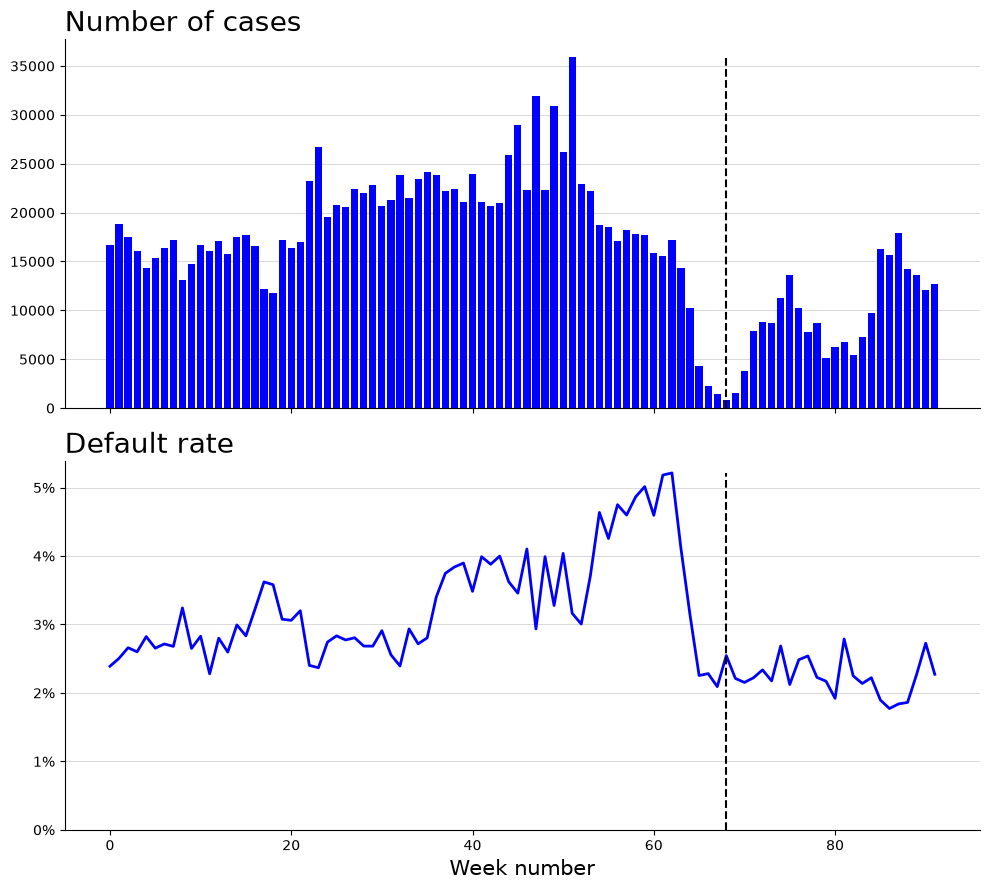

In [5]:
weekly = (pl.scan_parquet(PATH).group_by('WEEK_NUM')
          .agg(cases=pl.len(), defaults=pl.col('target').sum(), rate=pl.col('target').mean()).sort('WEEK_NUM').collect())
print(f'{weekly["defaults"].sum()} defaults in {weekly["cases"].sum()} cases, {weekly["defaults"].mean():.0f} per week on average')

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 9), sharex=True)
top.bar(weekly['WEEK_NUM'], weekly['cases'], width=0.8, color='blue')
top.set_title('Number of cases', loc='left', fontsize=20)
top.vlines(COVID, 0, weekly['cases'].max(), colors='black', linestyles='dashed')
bottom.plot(weekly['WEEK_NUM'], weekly['rate'], color='blue', linewidth=2)
bottom.set_ylim(0)
bottom.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
bottom.set_xlabel('Week number', fontsize=15)
bottom.set_title('Default rate', loc='left', fontsize=20)
bottom.vlines(COVID, 0, weekly['rate'].max(), colors='black', linestyles='dashed')
for ax in (top, bottom):
    ax.grid(axis='y', color='lightgray', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## Scorecard

Grouping, WOE and IV are estimated on the training data only. Numeric attributes are cut into deciles, rare categorical levels
are grouped into `other`, and missing values form their own group.

In [6]:
class FeatureEngineering:

    def __init__(self, bins=10, min_share=0.01):
        self.bins = bins            # number of bins for WOE transformation
        self.min_share = min_share  # rarer categorical levels are grouped into 'other'

    def group(self, train, c):
        # Missing values form their own group
        if train.schema[c].is_numeric():
            breaks = np.unique(np.quantile(train[c].drop_nulls().to_numpy(), np.arange(1, self.bins) / self.bins))
            return pl.col(c).cut(breaks).cast(pl.String).fill_null('missing')
        g = pl.col(c).cast(pl.String).fill_null('missing')
        shares = train.select(g)[c].value_counts(normalize=True)
        keep = shares.filter(pl.col('proportion') >= self.min_share)[c].to_list()
        return pl.when(g.is_in(keep) | (g == 'missing')).then(g).otherwise(pl.lit('other'))

    def fit(self, train):
        self.groups, self.tables, self.woe, self.iv = {}, {}, {}, {}
        for c in train.columns:
            if c in NON_FEATURES or train[c].n_unique() < 2:
                continue
            g = self.group(train, c)
            # WOE_j = log(D(n_j - D_j) / (D_j(n - D))), IV = sum_j ((n_j - D_j)/(n - D) - D_j/D) WOE_j
            # 0.5 is added to the counts so a group with no defaults (or only defaults) doesn't give an infinite WOE
            t = train.group_by(g.alias('group')).agg(n=pl.len(), D=pl.col('target').sum())
            t = t.with_columns(good=(pl.col('n') - pl.col('D') + 0.5) / (pl.col('n') - pl.col('D') + 0.5).sum(),
                               bad=(pl.col('D') + 0.5) / (pl.col('D') + 0.5).sum())
            t = t.with_columns(woe=(pl.col('good') / pl.col('bad')).log()).sort('group')
            self.groups[c] = g.alias('group')
            self.tables[c] = t
            self.woe[c] = g.replace_strict(t['group'], t['woe'], default=0.0).alias(c)  # unseen groups are neutral
            self.iv[c] = ((t['good'] - t['bad']) * t['woe']).sum()
        self.iv = dict(sorted(self.iv.items(), key=lambda kv: -kv[1]))
        return self

    def transform(self, df, cols=None):
        return df.select(self.woe[c] for c in cols or self.woe)

    def select(self, train, min_iv=0.02, max_corr=0.95):
        # Only keep predictive features with IV > 0.02 
        # correlated features are pruned by IV value
        cols = [c for c, iv in self.iv.items() if iv >= min_iv]
        corr = np.abs(np.corrcoef(self.transform(train, cols).to_numpy(), rowvar=False))
        keep = []
        for i in range(len(cols)):
            if all(corr[i, j] <= max_corr for j in keep):
                keep.append(i)
        return [cols[i] for i in keep]


class Scorecard:
    def __init__(self, min_iv=0.02, max_corr=0.95):
        self.min_iv, self.max_corr = min_iv, max_corr

    def fit(self, train):
        self.fe = FeatureEngineering().fit(train)
        self.features = self.fe.select(train, self.min_iv, self.max_corr)
        X = self.fe.transform(train, self.features).to_numpy()
        self.model = LogisticRegression(C=np.inf, max_iter=1000).fit(X, train['target'].to_numpy())
        return self

    def predict(self, df):
        # Probability of default
        return self.model.predict_proba(self.fe.transform(df, self.features).to_numpy())[:, 1]

## The models

In [7]:
data = pl.scan_parquet(PATH).gather_every(EVERY)
names = data.collect_schema().names()
internal = {c for f in INTERNAL for c in pl.scan_csv(DIR + f).collect_schema().names()}
sets = {'internal': [c for c in names if c in internal], 'internal + bureau': names}
train = data.filter(pl.col('WEEK_NUM') <= TRAIN_END).collect()
test = data.filter(pl.col('WEEK_NUM').is_between(TRAIN_END + 1, TEST_END)).collect()
print(f'train: {train.height} cases, weeks {train["WEEK_NUM"].min()}-{train["WEEK_NUM"].max()}, default rate {train["target"].mean():.4f}')
print(f'test:  {test.height} cases, weeks {test["WEEK_NUM"].min()}-{test["WEEK_NUM"].max()}, default rate {test["target"].mean():.4f}')

train: 1395111 cases, weeks 0-80, default rate 0.0324
test:  131548 cases, weeks 81-91, default rate 0.0212


In [8]:
period = (pl.when(pl.col('WEEK_NUM') > TRAIN_END).then(pl.lit('test'))
          .when(pl.col('WEEK_NUM') < COVID).then(pl.lit('train, before covid')).otherwise(pl.lit('train, after covid')))
scores = pl.concat([df.select('WEEK_NUM', 'target', period=period) for df in (train, test)])
for name, cols in sets.items():
    sc = Scorecard(MIN_IV, MAX_CORR).fit(train.select(cols))
    cats = [c for c in sc.features if not train.schema[c].is_numeric()]
    raw = [df.select(sc.features).with_columns(pl.col(cats).cast(pl.String).fill_null('missing')).to_pandas() for df in (train, test)]
    model = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6, random_seed=0, verbose=0, allow_writing_files=False,
                               cat_features=cats).fit(raw[0], train['target'].to_numpy())
    print(f'{name}: {len(sc.fe.iv)} attributes, {len(sc.features)} selected (IV >= {MIN_IV}, correlation <= {MAX_CORR}). Highest IV:')
    for c in list(sc.fe.iv)[:TOP]:
        print(f'  {c:45s} IV {sc.fe.iv[c]:.3f}{"" if c in sc.features else "  (left out, correlated)"}')
    scores = scores.with_columns(
        pl.Series(f'logistic, {name}', np.concatenate([sc.predict(df) for df in (train, test)])),
        pl.Series(f'catboost, {name}', np.concatenate([model.predict_proba(X)[:, 1] for X in raw])))
MODELS = scores.columns[3:]

internal: 164 attributes, 76 selected (IV >= 0.02, correlation <= 0.95). Highest IV:
  avgdpdtolclosure24_3658938P                   IV 0.310
  pctinstlsallpaidlate1d_3546856L               IV 0.278
  maxdbddpdtollast12m_3658940P                  IV 0.250
  pctinstlsallpaidlate4d_3546849L               IV 0.246
  avgdbddpdlast24m_3658932P                     IV 0.238
  pctinstlsallpaidlate6d_3546844L               IV 0.227
  daysoverduetolerancedd_3976961L               IV 0.221
  pctinstlsallpaidearl3d_427L                   IV 0.216
  maxdpdlast24m_143P                            IV 0.214
  numinstlswithdpd10_728L                       IV 0.214
  pctinstlsallpaidlat10d_839L                   IV 0.205
  lastrejectreason_759M                         IV 0.199
  maxdpdlast12m_727P                            IV 0.194
  maxdpdtolerance_374P                          IV 0.194
  lastrejectdate_50D                            IV 0.191
  maxdbddpdtollast6m_4187119P                   IV 0.186
  m

internal + bureau: 710 attributes, 204 selected (IV >= 0.02, correlation <= 0.95). Highest IV:
  avgdpdtolclosure24_3658938P                   IV 0.310
  mean_dpdmax_757P                              IV 0.291
  pctinstlsallpaidlate1d_3546856L               IV 0.278
  mean_dpdmax_139P                              IV 0.266
  mean_overdueamountmax_35A                     IV 0.259
  max_dpdmax_139P                               IV 0.255  (left out, correlated)
  mean_overdueamountmax2_398A                   IV 0.253  (left out, correlated)
  maxdbddpdtollast12m_3658940P                  IV 0.250
  pctinstlsallpaidlate4d_3546849L               IV 0.246
  max_dpdmax_757P                               IV 0.241
  avgdbddpdlast24m_3658932P                     IV 0.238
  mean_numberofoverdueinstlmax_1039L            IV 0.237
  sum_dpdmax_139P                               IV 0.237
  mean_overdueamountmax_155A                    IV 0.237
  max_numberofoverdueinstlmax_1039L             IV 0.232  (

## AUC

Uplift is the AUC with the bureau data minus the AUC without. Only the test rows are out of sample.

In [9]:
def aucs(scores, by):
    rows = [{by: k[0], 'cases': g.height, **{m: roc_auc_score(g['target'], g[m]) for m in MODELS}}
            for k, g in scores.group_by(by, maintain_order=True)]
    return pl.DataFrame(rows).with_columns((pl.col(f'{m}, internal + bureau') - pl.col(f'{m}, internal')).alias(f'{m}, uplift')
                                           for m in ('logistic', 'catboost'))


weekly_auc = aucs(scores.sort('WEEK_NUM'), 'WEEK_NUM')
with pl.Config(tbl_cols=10, float_precision=4):
    display(aucs(scores, 'period'))
for name, w in (('all weeks', weekly_auc), ('test weeks', weekly_auc.filter(pl.col('WEEK_NUM') > TRAIN_END))):
    print(f'average weekly AUC uplift from bureau data, {name}: logistic {w["logistic, uplift"].mean():+.4f}, catboost {w["catboost, uplift"].mean():+.4f}')

period,cases,"logistic, internal","catboost, internal","logistic, internal + bureau","catboost, internal + bureau","logistic, uplift","catboost, uplift"
str,i64,f64,f64,f64,f64,f64,f64
"""train, before covid""",1300320,0.7467,0.7682,0.8094,0.8268,0.0627,0.0586
"""train, after covid""",94791,0.7802,0.8008,0.8348,0.8489,0.0546,0.0481
"""test""",131548,0.7951,0.8127,0.8424,0.8559,0.0473,0.0433


average weekly AUC uplift from bureau data, all weeks: logistic +0.0587, catboost +0.0551
average weekly AUC uplift from bureau data, test weeks: logistic +0.0471, catboost +0.0426


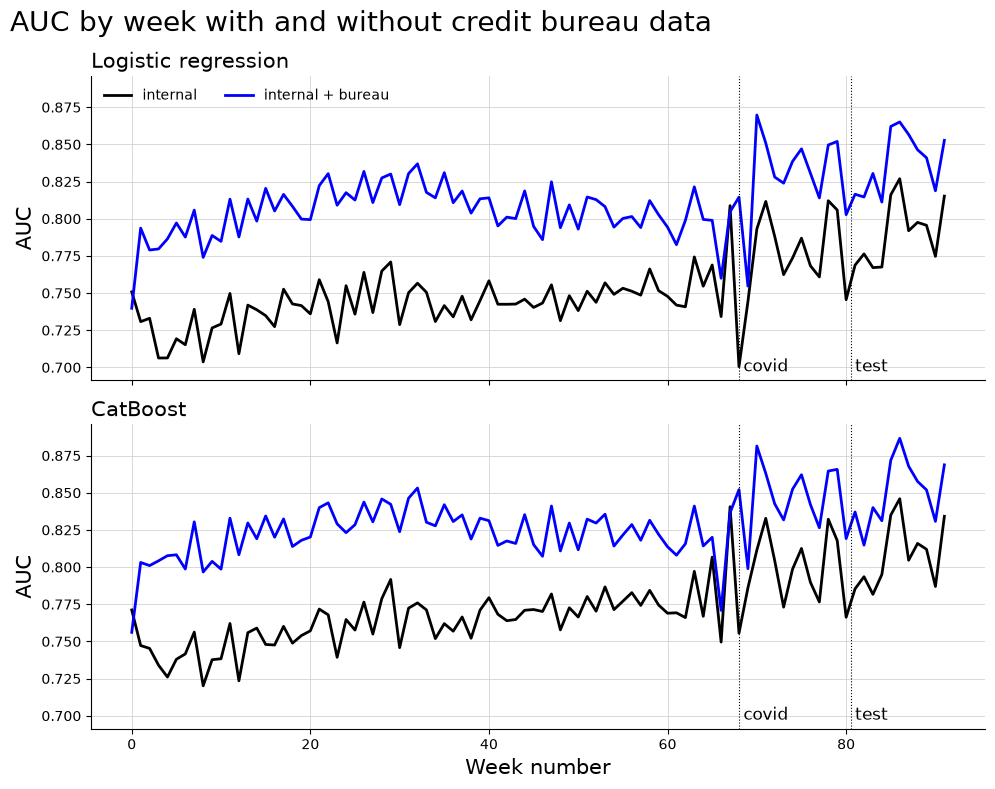

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, m in zip(axes, ('logistic', 'catboost')):
    for name, color in zip(sets, ('black', 'blue')):
        ax.plot(weekly_auc['WEEK_NUM'], weekly_auc[f'{m}, {name}'], color=color, linewidth=2, label=name)
    for week, label in ((COVID, 'covid'), (TRAIN_END + 0.5, 'test')):
        ax.axvline(week, color='black', linewidth=0.8, linestyle=':')
        ax.text(week + 0.5, 0.03, label, fontsize=12, color='black', transform=ax.get_xaxis_transform())
    ax.set_ylabel('AUC', fontsize=15)
    ax.set_title({'logistic': 'Logistic regression', 'catboost': 'CatBoost'}[m], loc='left', fontsize=15)
    ax.grid(color='lightgray', linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, loc='upper left', ncols=2)
axes[1].set_xlabel('Week number', fontsize=15)
fig.suptitle('AUC by week with and without credit bureau data', x=0.01, ha='left', fontsize=20)
fig.tight_layout()
plt.show()

## Calibration

Actual default rate against the mean predicted PD of each model.

In [11]:
def calibration(scores):
    return scores.group_by('period', maintain_order=True).agg(pl.len().alias('cases'), pl.col('target').mean().alias('actual'),
                                                              pl.col(MODELS).mean())


with pl.Config(tbl_cols=10, float_precision=4):
    display(calibration(scores))

period,cases,actual,"logistic, internal","catboost, internal","logistic, internal + bureau","catboost, internal + bureau"
str,u32,f64,f64,f64,f64,f64
"""train, before covid""",1300320,0.0331,0.0322,0.0322,0.0327,0.0326
"""train, after covid""",94791,0.0230,0.0341,0.0342,0.0276,0.0275
"""test""",131548,0.0212,0.0330,0.0340,0.0283,0.0288


PD's are recallibrated after onset of covid

In [12]:
start = TRAIN_END - RECAL + 1
recent = scores.filter(pl.col('WEEK_NUM').is_between(start, TRAIN_END))
print(f'default rate in weeks {start}-{TRAIN_END}: {recent["target"].mean():.4f}')
for m in MODELS:
    shift = brentq(lambda d: expit(logit(recent[m].to_numpy()) + d).mean() - recent['target'].mean(), -5, 5)
    print(f'{m}: intercept shifted by {shift:+.3f} from week {start} on')
    scores = scores.with_columns(pl.when(pl.col('WEEK_NUM') >= start).then(1 / (1 + (1 / pl.col(m) - 1) * np.exp(-shift))).otherwise(pl.col(m)).alias(m))

with pl.Config(tbl_cols=10, float_precision=4):
    display(calibration(scores))

default rate in weeks 68-80: 0.0230
logistic, internal: intercept shifted by -0.424 from week 68 on
catboost, internal: intercept shifted by -0.429 from week 68 on
logistic, internal + bureau: intercept shifted by -0.199 from week 68 on


catboost, internal + bureau: intercept shifted by -0.195 from week 68 on


period,cases,actual,"logistic, internal","catboost, internal","logistic, internal + bureau","catboost, internal + bureau"
str,u32,f64,f64,f64,f64,f64
"""train, before covid""",1300320,0.0331,0.0322,0.0322,0.0327,0.0326
"""train, after covid""",94791,0.0230,0.0230,0.0230,0.0230,0.0230
"""test""",131548,0.0212,0.0222,0.0228,0.0236,0.0241


## Loss avoided and net benefit

Expected loss is EL = PD x LGD x EAD. Every case in the data was approved by the lender, so a model can only turn approved cases
into rejections. It avoids the loss LGD x EAD on the rejected cases that defaulted, and turns away the lending to the rejected
cases that did not default, which costs MARGIN x EAD. Applicants the lender rejected are not in the data, so good applicants a
model would have let in are not counted.

On the test weeks, every model rejects the same share `REJECT` of the cases that it gives the highest PD. The models are then
compared at the same operating point, and the result depends only on how each model ranks the cases, not on its calibration.
With these assumptions rejecting a case pays when PD x LGD > (1 - PD) x MARGIN, a PD above MARGIN / (MARGIN + LGD); the PD
cut-off column shows the recalibrated PD each model's rejections start at.

In [13]:
t = scores.with_columns(ead=pl.concat([df[EAD] for df in (train, test)])).filter(pl.col('period') == 'test')
y, ead = t['target'].to_numpy(), t['ead'].to_numpy()
pds = {m: t[m].to_numpy() for m in MODELS}
loss = LGD * (ead * y).sum()


def rejected(p, share):
    # The share of the cases with the highest PD
    return np.argsort(-p)[:int(share * len(p))]


rows = []
for m in MODELS:
    r = rejected(pds[m], REJECT)
    rows.append({'model': m, 'rejected': len(r), 'PD cut-off': pds[m][r].min(), 'defaults among rejected': y[r].sum(),
                 'loss avoided': LGD * (ead[r] * y[r]).sum(), 'share of loss': LGD * (ead[r] * y[r]).sum() / loss,
                 'good lending turned away': (ead[r] * (1 - y[r])).sum()})
    rows[-1]['net benefit'] = rows[-1]['loss avoided'] - MARGIN * rows[-1]['good lending turned away']
print(f'Test weeks: {len(y)} cases, {y.sum()} defaults, lending {ead.sum():,.0f}, loss {loss:,.0f} (LGD {LGD}). '
      f'Rejecting the {REJECT:.0%} with the highest PD; rejecting pays above a PD of {MARGIN / (MARGIN + LGD):.3f}:')
with pl.Config(tbl_cols=10, float_precision=3, thousands_separator=',', fmt_str_lengths=30):
    display(pl.DataFrame(rows))
net = {r['model']: r['net benefit'] for r in rows}
for m in ('logistic', 'catboost'):
    value = net[f'{m}, internal + bureau'] - net[f'{m}, internal']
    print(f'{m}: net benefit of the bureau data {value:,.0f}, {value / ead.sum():.4%} of the lending in the test weeks, {value / len(y):.1f} per application')

Test weeks: 131548 cases, 2788 defaults, lending 7,378,852,448, loss 93,668,218 (LGD 0.5). Rejecting the 3% with the highest PD; rejecting pays above a PD of 0.138:


model,rejected,PD cut-off,defaults among rejected,loss avoided,share of loss,good lending turned away,net benefit
str,i64,f64,i64,f64,f64,f64,f64
"""logistic, internal""","3,946",0.091,567,"20,336,265.606",0.217,"226,885,136.949","2,185,454.651"
"""catboost, internal""","3,946",0.094,687,"28,185,220.116",0.301,"229,062,845.354","9,860,192.487"
"""logistic, internal + bureau""","3,946",0.114,671,"25,642,755.106",0.274,"218,781,629.742","8,140,224.727"
"""catboost, internal + bureau""","3,946",0.111,814,"33,015,872.815",0.352,"217,271,119.877","15,634,183.224"


logistic: net benefit of the bureau data 5,954,770, 0.0807% of the lending in the test weeks, 45.3 per application
catboost: net benefit of the bureau data 5,773,991, 0.0783% of the lending in the test weeks, 43.9 per application


## Uncertainty

The test cases are resampled with replacement `BOOT` times. For each resample the AUCs and the net benefits at the rejection
share `REJECT` are recalculated, and the 2.5% and 97.5% percentiles give a 95% interval, first for the AUC of each model and then for
the differences between the models. The models are
not refitted, so the intervals cover the sampling of the test cases only. Net benefit is a share of lending.

In [14]:
def measures(i):
    # AUC and net benefit / lending of each model on the test cases i
    out = {}
    for m in MODELS:
        r = i[rejected(pds[m][i], REJECT)]
        out['AUC', m] = roc_auc_score(y[i], pds[m][i])
        out['net benefit', m] = (LGD * ead[r] * y[r] - MARGIN * ead[r] * (1 - y[r])).sum() / ead[i].sum()
    return out


def interval(estimate, values):
    return {'estimate': estimate, 'low': np.quantile(values, 0.025), 'high': np.quantile(values, 0.975)}


rng = np.random.default_rng(0)
full = measures(np.arange(len(y)))
boot = [measures(rng.integers(0, len(y), len(y))) for _ in range(BOOT)]
with pl.Config(float_precision=5, fmt_str_lengths=45):
    display(pl.DataFrame([{'model': m, **interval(full['AUC', m], [s['AUC', m] for s in boot])} for m in MODELS]))

model,estimate,low,high
str,f64,f64,f64
"""logistic, internal""",0.79508,0.78744,0.80325
"""catboost, internal""",0.81266,0.80501,0.82049
"""logistic, internal + bureau""",0.84242,0.83522,0.84848
"""catboost, internal + bureau""",0.85592,0.84932,0.86236


In [15]:
DIFFS = [('bureau data, logistic', 'logistic, internal + bureau', 'logistic, internal'),
         ('bureau data, catboost', 'catboost, internal + bureau', 'catboost, internal'),
         ('catboost - logistic, internal', 'catboost, internal', 'logistic, internal'),
         ('catboost - logistic, internal + bureau', 'catboost, internal + bureau', 'logistic, internal + bureau')]
rows = []
for k in ('AUC', 'net benefit'):
    for name, a, b in DIFFS:
        d = np.array([s[k, a] - s[k, b] for s in boot])
        rows.append({'measure': k, 'difference': name, **interval(full[k, a] - full[k, b], d), 'share above 0': (d > 0).mean()})
with pl.Config(tbl_rows=20, float_precision=5, fmt_str_lengths=45):
    display(pl.DataFrame(rows))

measure,difference,estimate,low,high,share above 0
str,str,f64,f64,f64,f64
"""AUC""","""bureau data, logistic""",0.04734,0.04163,0.05281,1.00000
"""AUC""","""bureau data, catboost""",0.04326,0.03811,0.04848,1.00000
"""AUC""","""catboost - logistic, internal""",0.01758,0.01418,0.02091,1.00000
"""AUC""","""catboost - logistic, internal + bureau""",0.01350,0.01069,0.01635,1.00000
"""net benefit""","""bureau data, logistic""",0.00081,0.00050,0.00110,1.00000
"""net benefit""","""bureau data, catboost""",0.00078,0.00053,0.00103,1.00000
"""net benefit""","""catboost - logistic, internal""",0.00104,0.00074,0.00133,1.00000
"""net benefit""","""catboost - logistic, internal + bureau""",0.00102,0.00074,0.00126,1.00000
